# Γεωμετρική αναζήτηση.

### Βοηθητικές βιβλιοθήκες για την υλοποίηση και παρουσίαση των αλγορίθμων

In [1]:
import matplotlib.pyplot as plt
import numpy as np

### 1. Υλοποίηση του αλγορίθμου κατασκευής Kd-Tree και οπτικοποίηση των βημάτων κατασκευής του

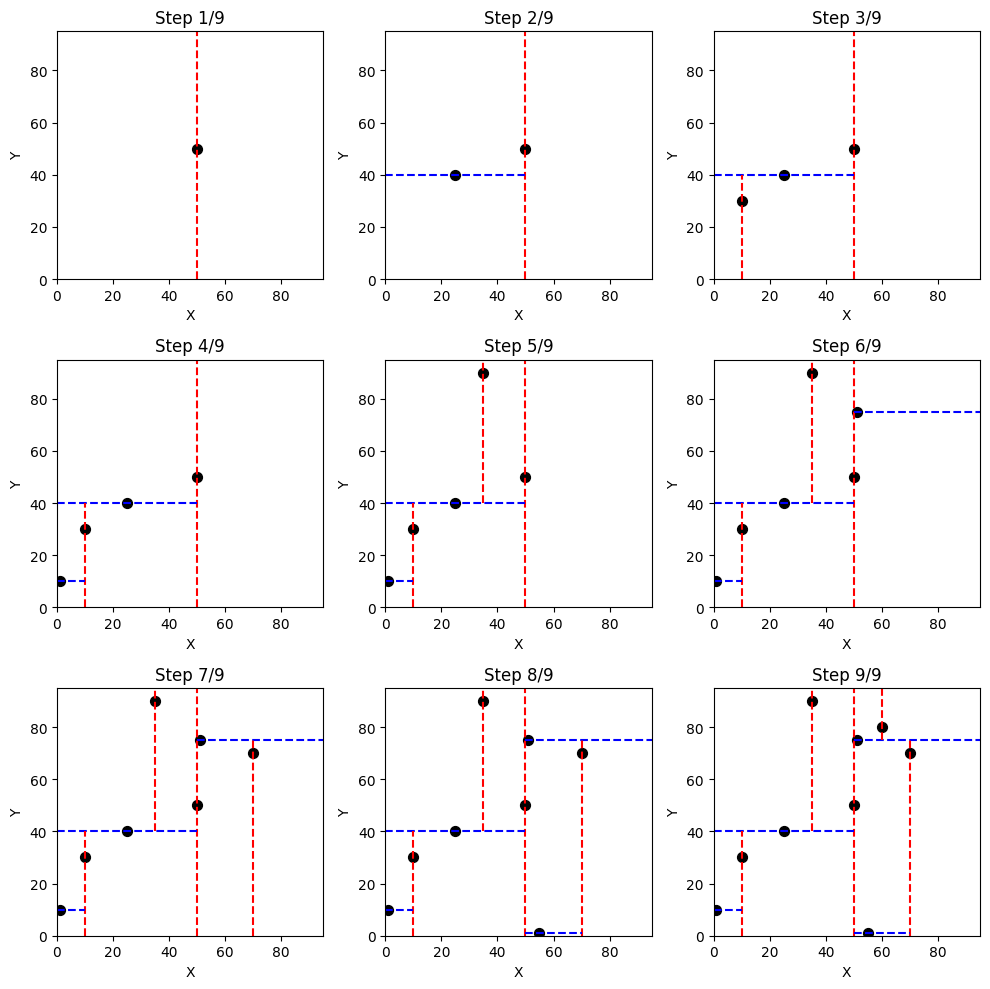

In [ ]:
points = np.array([(1,10), (10,30), (25,40), (35,90), (50,50), (51,75), (55,1), (60,80), (70,70)])

class KDNode:
    def __init__(self, point, left=None, right=None, axis=0):
        self.point = point
        self.left = left
        self.right = right
        self.axis = axis

# build kd-tree only
def build_kdtree(points, depth=0):
    if len(points) == 0:
        return None
    k = points.shape[1]
    axis = depth % k
    points = points[points[:, axis].argsort()]
    median_idx = len(points) // 2
    median_point = points[median_idx]
    left = build_kdtree(points[:median_idx], depth+1)
    right = build_kdtree(points[median_idx+1:], depth+1)
    return KDNode(median_point, left, right, axis)

# build + collect steps for visualization
def collect_kdtree_steps(points, depth=0, x_min=0, x_max=95, y_min=0, y_max=95, steps=None):
    if steps is None:
        steps = []
    if len(points) == 0:
        return None, steps
    k = points.shape[1]
    axis = depth % k
    points = points[points[:, axis].argsort()]
    median_idx = len(points) // 2
    median_point = points[median_idx]
    
    # store current step
    steps.append((median_point, axis, x_min, x_max, y_min, y_max))
    
    left, steps = collect_kdtree_steps(points[:median_idx], depth+1,
                                       x_min if axis==0 else x_min,
                                       median_point[0] if axis==0 else x_max,
                                       y_min if axis==1 else y_min,
                                       median_point[1] if axis==1 else y_max,
                                       steps)
    right, steps = collect_kdtree_steps(points[median_idx+1:], depth+1,
                                        median_point[0] if axis==0 else x_min,
                                        x_max if axis==0 else x_max,
                                        median_point[1] if axis==1 else y_min,
                                        y_max if axis==1 else y_max,
                                        steps)
    return KDNode(median_point, left, right, axis), steps

# visualize kd-tree steps
def visualize_kdtree_steps_grid(steps):
    fig, axes = plt.subplots(3, 3, figsize=(10,10))  # 3x3 grid
    axes = axes.flatten()

    for i, step in enumerate(steps):
        ax = axes[i]
        for j in range(i+1):
            pt, ax_type, xm, xM, ym, yM = steps[j]
            ax.scatter(pt[0], pt[1], c='k', s=50)
            if ax_type == 0:  # Κατακόρυφη
                ax.plot([pt[0], pt[0]], [ym, yM], 'r--')
            else:  # Οριζόντια
                ax.plot([xm, xM], [pt[1], pt[1]], 'b--')
        ax.set_xlim(0,95)
        ax.set_ylim(0,95)
        ax.set_xlabel('X')
        ax.set_ylabel('Y')
        ax.set_title(f'Step {i+1}/{len(steps)}')

    # remove empty subplots if needed
    for j in range(len(steps), 9):
        fig.delaxes(axes[j])
    
    plt.tight_layout()
    plt.show()

# build tree + collect steps
tree2, steps = collect_kdtree_steps(points)

# visualize
visualize_kdtree_steps_grid(steps)


Σε κάθε επίπεδο, τα σημεία ταξινομούνται ως προς τον άξονα που αντιστοιχεί στο βάθος (x στα άρτια επίπεδα, y στα περιττά) και ο διάμεσός τους γίνεται ρίζα του υποδέντρου, ενώ τα υπόλοιπα χωρίζονται σε αριστερό και δεξί παιδί. Η ταξινόμηση σε κάθε επίπεδο κοστίζει O(n log n), άρα η κατασκευή κοστίζει συνολικά O(n log² n). Το ύψος του δέντρου είναι O(log n).

### 2. Υλοποίηση του αλγορίθμου Ορθογώνιας Γεωμετρικής Αναζήτησης σε Kd-Tree

In [3]:
# rectangular range search in kd-tree
def range_search_kdtree(node, x_min, x_max, y_min, y_max, found=None):
    if found is None:
        found = []
    if node is None:
        return found
    
    x, y = node.point
    axis = node.axis
    
    # check if point is inside the query rectangle
    if x_min <= x <= x_max and y_min <= y <= y_max:
        found.append(node.point)
    
    # recursive search depending on axis
    if axis == 0:  # vertical split, x-axis
        if x_min <= x:
            range_search_kdtree(node.left, x_min, x_max, y_min, y_max, found)
        if x <= x_max:
            range_search_kdtree(node.right, x_min, x_max, y_min, y_max, found)
    else:  # horizontal split, y-axis
        if y_min <= y:
            range_search_kdtree(node.left, x_min, x_max, y_min, y_max, found)
        if y <= y_max:
            range_search_kdtree(node.right, x_min, x_max, y_min, y_max, found)
    
    return found

Η αναζήτηση επισκέπτεται ένα υποδέντρο μόνο αν το ορθογώνιο τέμνει την περιοχή που αντιστοιχεί σε αυτό. Για n σημεία και k σημεία στο αποτέλεσμα, ο χρόνος είναι O(√n + k) στη χειρότερη περίπτωση.

### 3. Εφαρμογή Ορθογώνιας Γεωμετρικής Αναζήτησης σε 120 τυχαία σημεία με χρήση Kd-Tree

Number of points inside Rectangle: 31/120


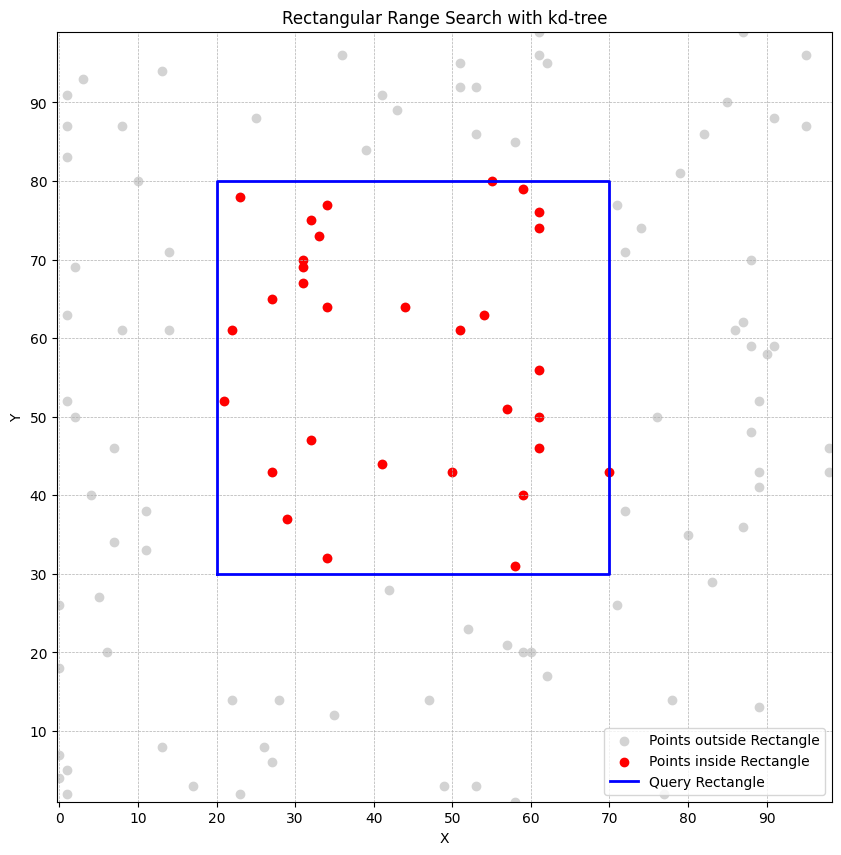

In [4]:
# generate 120 random points
np.random.seed(42)
P = np.random.randint(0, 100, size=(120,2))

# build kd-tree
tree = build_kdtree(P)

# define rectangular query region
x_min, x_max = 20, 70
y_min, y_max = 30, 80

# perform range search
points_in_rect = range_search_kdtree(tree, x_min, x_max, y_min, y_max)
print(f"Number of points inside Rectangle: {len(points_in_rect)}/120")

# plot results
plt.figure(figsize=(10,10))
plt.scatter(P[:, 0], P[:, 1], c='lightgray', label='Points outside Rectangle')

points_in_rect = np.array(points_in_rect)
plt.scatter(points_in_rect[:, 0], points_in_rect[:, 1], c='red', label='Points inside Rectangle')

plt.plot([x_min, x_max, x_max, x_min, x_min],
         [y_min, y_min, y_max, y_max, y_min],
         'b-', lw=2, label='Query Rectangle')

plt.xlabel('X')
plt.ylabel('Y')
plt.title('Rectangular Range Search with kd-tree')
plt.legend(loc='lower right')

plt.xticks(np.arange(0, 101, 10))
plt.yticks(np.arange(0, 101, 10))
plt.grid(True, linestyle='--', linewidth=0.5)

plt.margins(0)

plt.axis('equal') 
plt.show()

In [ ]:
# verify against a brute-force scan
expected = [p for p in P if x_min <= p[0] <= x_max and y_min <= p[1] <= y_max]
print("Matches brute force:", sorted(map(tuple, points_in_rect)) == sorted(map(tuple, expected)))

Για 120 τυχαία σημεία και το ορθογώνιο [20, 70] × [30, 80], βρέθηκαν 31 σημεία. Το σύνολο ταυτίζεται με αυτό μιας εξαντλητικής σάρωσης.